In [4]:
import pandas as pd

#Loaded the customer dataset
df = pd.read_csv("data/raw/Telco-Customer-Churn.csv")

#Display the first five rows
print(df.head())

#Display the number of rows and columns
print("Dataset shape:",df.shape)

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

In [5]:
#Display the information of every column
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [6]:
#count missing values in each column
missing_values = df.isnull().sum()
print(missing_values)

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [7]:
#count completely duplicated rows
duplicated_count = df.duplicated().sum()
print(duplicated_count)

0


In [8]:
#summary statistics for numerical values
print(df.describe())

       SeniorCitizen       tenure  MonthlyCharges
count    7043.000000  7043.000000     7043.000000
mean        0.162147    32.371149       64.761692
std         0.368612    24.559481       30.090047
min         0.000000     0.000000       18.250000
25%         0.000000     9.000000       35.500000
50%         0.000000    29.000000       70.350000
75%         0.000000    55.000000       89.850000
max         1.000000    72.000000      118.750000


In [9]:
#check the current data type
print("Current dtype:", df["TotalCharges"].dtype)

#Display few values
print(df["TotalCharges"].head(10).tolist())

#Count empty or whitespace-only strings
empty_string = (
    df["TotalCharges"]
    .astype(str)
    .str.strip()
    .eq("")
    .sum()
)
print("Empty or whitespace-only values:",empty_string)

Current dtype: object
['29.85', '1889.5', '108.15', '1840.75', '151.65', '820.5', '1949.4', '301.9', '3046.05', '3487.95']
Empty or whitespace-only values: 11


In [10]:
total_charges_numeric = pd.to_numeric(
    df["TotalCharges"].astype(str).str.strip(),
    errors = "coerce"
)

print("Values that failed numeric conversion:",
      total_charges_numeric.isna().sum())

Values that failed numeric conversion: 11


In [11]:
# Count customers in each churn category
print(df["Churn"].value_counts())

# Show the percentage of customers in each category
print(
    df["Churn"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


In [12]:
# Find customers whose TotalCharges is blank or contains only spaces
blank_mask = (
    df["TotalCharges"]
    .astype(str)
    .str.strip()
    .eq("")
)

# Display the relevant columns for those customers
print(df.loc[blank_mask, ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]])

      customerID  tenure  MonthlyCharges TotalCharges
488   4472-LVYGI       0           52.55             
753   3115-CZMZD       0           20.25             
936   5709-LVOEQ       0           80.85             
1082  4367-NUYAO       0           25.75             
1340  1371-DWPAZ       0           56.05             
3331  7644-OMVMY       0           19.85             
3826  3213-VVOLG       0           25.35             
4380  2520-SGTTA       0           20.00             
5218  2923-ARZLG       0           19.70             
6670  4075-WKNIU       0           73.35             
6754  2775-SEFEE       0           61.90             


In [13]:
# Convert TotalCharges from text to numeric values
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].astype(str).str.strip(),
    errors="coerce"
)

# Replace missing TotalCharges with 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# Verify the cleaning
print("Data type:", df["TotalCharges"].dtype)
print("Missing values:", df["TotalCharges"].isna().sum())
print("TotalCharges for zero-tenure customers:")
print(df.loc[df["tenure"] == 0, ["tenure", "MonthlyCharges", "TotalCharges"]])

Data type: float64
Missing values: 0
TotalCharges for zero-tenure customers:
      tenure  MonthlyCharges  TotalCharges
488        0           52.55           0.0
753        0           20.25           0.0
936        0           80.85           0.0
1082       0           25.75           0.0
1340       0           56.05           0.0
3331       0           19.85           0.0
3826       0           25.35           0.0
4380       0           20.00           0.0
5218       0           19.70           0.0
6670       0           73.35           0.0
6754       0           61.90           0.0


In [14]:
# Check the dataset dimensions
print("Dataset shape:", df.shape)

# Check all data types and non-missing counts
df.info()

# Verify missing values in every column
print("\nMissing values per column:")
print(df.isnull().sum())

# Verify duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

Dataset shape: (7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling

Churn
No     5174
Yes    1869
Name: count, dtype: int64


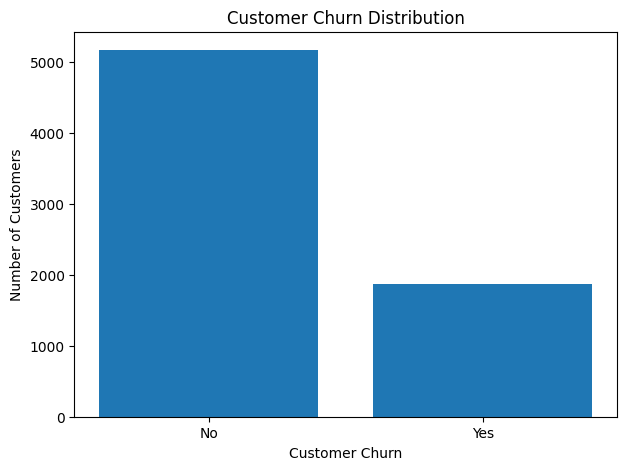

In [15]:
import matplotlib.pyplot as plt

# Count customers in each churn category
churn_counts = df["Churn"].value_counts()

# Display the counts
print(churn_counts)

# Create a bar chart
plt.figure(figsize=(7, 5))
plt.bar(churn_counts.index, churn_counts.values)

# Add labels and title
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")
plt.title("Customer Churn Distribution")

# Display the chart
plt.show()

In [16]:
# Calculate average tenure for each churn category
tenure_by_churn = df.groupby("Churn")["tenure"].mean()

print(tenure_by_churn)

Churn
No     37.569965
Yes    17.979133
Name: tenure, dtype: float64


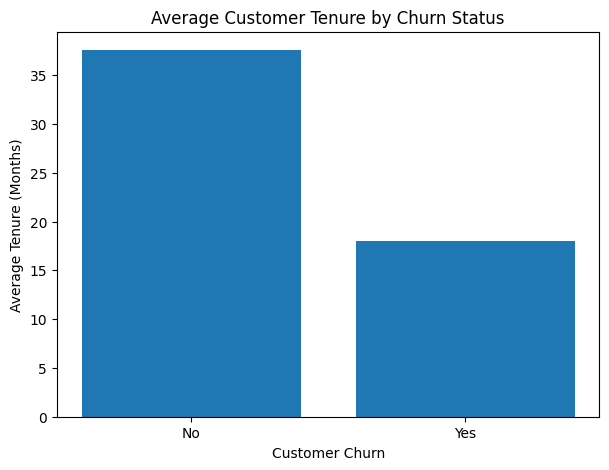

In [17]:
plt.figure(figsize=(7, 5))

plt.bar(tenure_by_churn.index, tenure_by_churn.values)

plt.xlabel("Customer Churn")
plt.ylabel("Average Tenure (Months)")
plt.title("Average Customer Tenure by Churn Status")

plt.show()

In [18]:
# Count customers by contract type and churn status
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"]
)

print(contract_churn)

Churn             No   Yes
Contract                  
Month-to-month  2220  1655
One year        1307   166
Two year        1647    48


In [19]:
# Calculate the percentage distribution within each contract type
contract_churn_rate = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print(contract_churn_rate.round(2))

Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


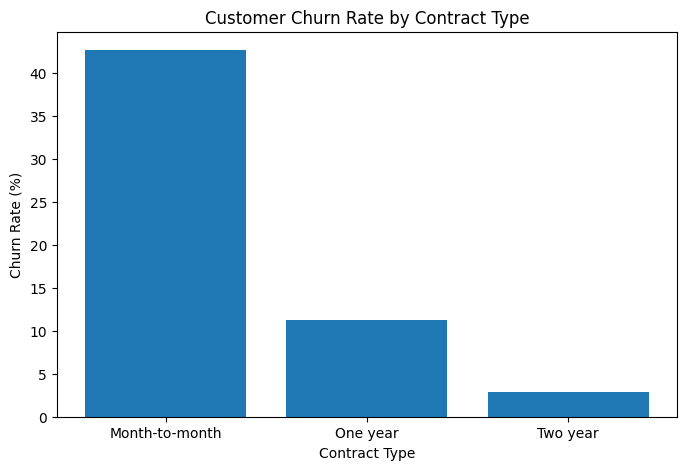

In [20]:
# Select the churn percentage for each contract type
churn_rates = contract_churn_rate["Yes"]

# Create a bar chart
plt.figure(figsize=(8, 5))
plt.bar(churn_rates.index, churn_rates.values)

# Add labels
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.title("Customer Churn Rate by Contract Type")

plt.show()

In [21]:
# Calculate average monthly charges for each churn category
charges_by_churn = df.groupby("Churn")["MonthlyCharges"].mean()

print(charges_by_churn)

Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64


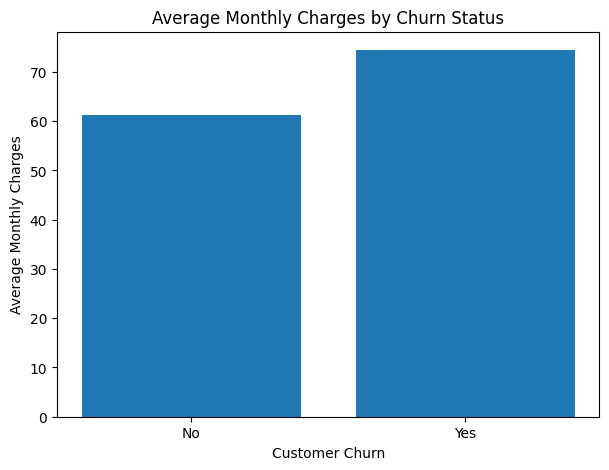

In [22]:
plt.figure(figsize=(7, 5))

plt.bar(charges_by_churn.index, charges_by_churn.values)

plt.xlabel("Customer Churn")
plt.ylabel("Average Monthly Charges")
plt.title("Average Monthly Charges by Churn Status")

plt.show()

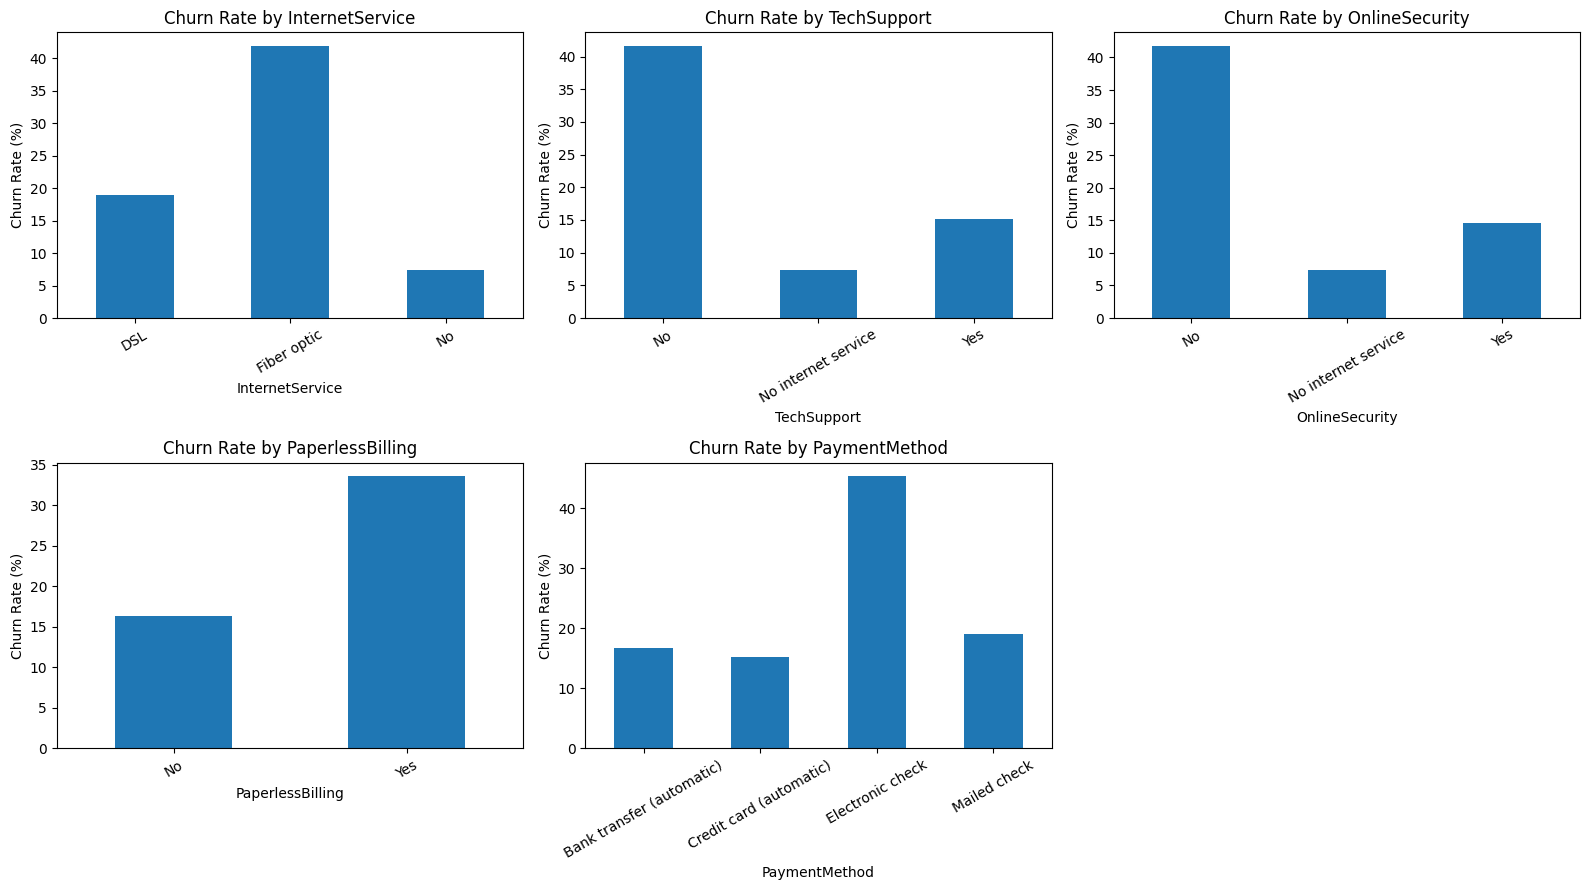

In [23]:
# Select categorical features to investigate
categorical_features = [
    "InternetService",
    "TechSupport",
    "OnlineSecurity",
    "PaperlessBilling",
    "PaymentMethod"
]

# Create a figure with one subplot for each feature
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

# Calculate and plot churn rate for each feature
for i, feature in enumerate(categorical_features):
    churn_rate = pd.crosstab(
        df[feature],
        df["Churn"],
        normalize="index"
    )["Yes"] * 100

    churn_rate.plot(kind="bar", ax=axes[i])

    axes[i].set_title(f"Churn Rate by {feature}")
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Churn Rate (%)")
    axes[i].tick_params(axis="x", rotation=30)

# Hide the unused sixth subplot
axes[5].set_visible(False)

plt.tight_layout()
plt.show()

In [24]:
# Remove the customer identifier from the model inputs
X = df.drop(columns=["customerID", "Churn"])

# The target we want to predict
y = df["Churn"]

print("Feature data shape:", X.shape)
print("Target data shape:", y.shape)

print("\nTarget categories:")
print(y.value_counts())

Feature data shape: (7043, 19)
Target data shape: (7043,)

Target categories:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [25]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training features: (5634, 19)
Testing features: (1409, 19)
Training targets: (5634,)
Testing targets: (1409,)


In [26]:
# Identify categorical and numerical columns
categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

print("\nNumber of categorical features:", len(categorical_features))
print("Number of numerical features:", len(numerical_features))

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Number of categorical features: 15
Number of numerical features: 4


In [27]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Process categorical and numerical features separately
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        )
    ]
)

# Combine preprocessing and Logistic Regression
model_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(max_iter=1000))
    ]
)

print("Preprocessing and model pipeline created successfully!")

Preprocessing and model pipeline created successfully!


In [30]:
# Train the pipeline using the training data
model_pipeline.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [29]:
# Predict customer churn on the test dataset
y_pred = model_pipeline.predict(X_test)

print("Predictions generated successfully!")
print("\nFirst 10 actual labels:")
print(y_test.head(10).tolist())

print("\nFirst 10 predicted labels:")
print(y_pred[:10].tolist())

Predictions generated successfully!

First 10 actual labels:
['No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'Yes']

First 10 predicted labels:
['No', 'Yes', 'No', 'No', 'No', 'Yes', 'No', 'No', 'No', 'No']


In [31]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label="Yes")
recall = recall_score(y_test, y_pred, pos_label="Yes")
f1 = f1_score(y_test, y_pred, pos_label="Yes")

print("MODEL EVALUATION RESULTS")
print("-" * 35)
print(f"Accuracy:  {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=["No", "Yes"]))

MODEL EVALUATION RESULTS
-----------------------------------
Accuracy:  0.8055 (80.55%)
Precision: 0.6572
Recall:    0.5588
F1-score:  0.6040

Classification Report:
              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1035
         Yes       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

Confusion Matrix:
[[926 109]
 [165 209]]


In [32]:
from sklearn.base import clone

# Create a second model that gives more weight to both classes equally
balanced_model = clone(model_pipeline)
balanced_model.set_params(
    model__class_weight="balanced"
)

# Train the new model on the same training data
balanced_model.fit(X_train, y_train)

# Predict on the same test data
y_pred_balanced = balanced_model.predict(X_test)

# Compare performance
print("BASELINE MODEL")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Churn precision:", round(
    precision_score(y_test, y_pred, pos_label="Yes"), 4
))
print("Churn recall:", round(
    recall_score(y_test, y_pred, pos_label="Yes"), 4
))
print("Churn F1-score:", round(
    f1_score(y_test, y_pred, pos_label="Yes"), 4
))

print("\nBALANCED MODEL")
print("Accuracy:", round(accuracy_score(y_test, y_pred_balanced), 4))
print("Churn precision:", round(
    precision_score(y_test, y_pred_balanced, pos_label="Yes"), 4
))
print("Churn recall:", round(
    recall_score(y_test, y_pred_balanced, pos_label="Yes"), 4
))
print("Churn F1-score:", round(
    f1_score(y_test, y_pred_balanced, pos_label="Yes"), 4
))

BASELINE MODEL
Accuracy: 0.8055
Churn precision: 0.6572
Churn recall: 0.5588
Churn F1-score: 0.604

BALANCED MODEL
Accuracy: 0.7381
Churn precision: 0.5043
Churn recall: 0.7834
Churn F1-score: 0.6136


                 Baseline  Balanced
Accuracy           0.8055    0.7381
Churn Precision    0.6572    0.5043
Churn Recall       0.5588    0.7834
Churn F1-score     0.6040    0.6136


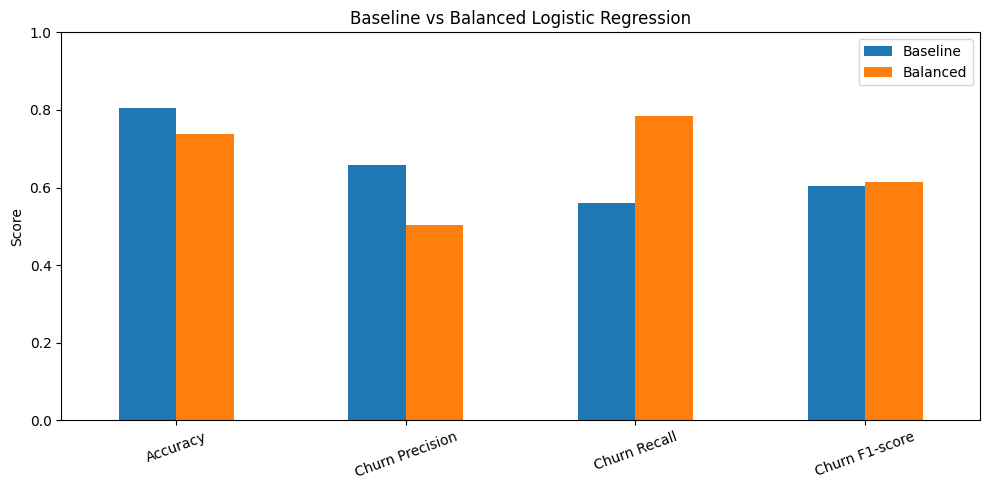

In [33]:
import pandas as pd
import matplotlib.pyplot as plt

model_comparison = pd.DataFrame({
    "Baseline": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, pos_label="Yes"),
        recall_score(y_test, y_pred, pos_label="Yes"),
        f1_score(y_test, y_pred, pos_label="Yes")
    ],
    "Balanced": [
        accuracy_score(y_test, y_pred_balanced),
        precision_score(y_test, y_pred_balanced, pos_label="Yes"),
        recall_score(y_test, y_pred_balanced, pos_label="Yes"),
        f1_score(y_test, y_pred_balanced, pos_label="Yes")
    ]
}, index=["Accuracy", "Churn Precision", "Churn Recall", "Churn F1-score"])

print(model_comparison.round(4))

model_comparison.plot(kind="bar", figsize=(10, 5))
plt.title("Baseline vs Balanced Logistic Regression")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [34]:
# Select one customer from the test dataset
sample_customer = X_test.iloc[[0]]

# Predict using the balanced model
sample_prediction = balanced_model.predict(sample_customer)[0]

# Get the estimated probability of churn
sample_probability = balanced_model.predict_proba(
    sample_customer
)[0]

# Find the probability corresponding to "Yes"
classes = balanced_model.named_steps["model"].classes_
churn_index = list(classes).index("Yes")
churn_probability = sample_probability[churn_index]

print("CUSTOMER CHURN PREDICTION")
print("-" * 35)
print("Predicted churn:", sample_prediction)
print(f"Estimated churn probability: {churn_probability:.2%}")

CUSTOMER CHURN PREDICTION
-----------------------------------
Predicted churn: No
Estimated churn probability: 11.77%


Balanced Model - Confusion Matrix:
[[747 288]
 [ 81 293]]

Balanced Model - Classification Report:
              precision    recall  f1-score   support

          No       0.90      0.72      0.80      1035
         Yes       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



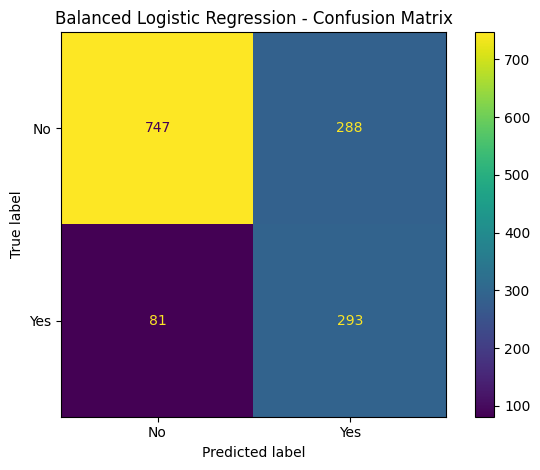

In [35]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Evaluate the balanced model
balanced_cm = confusion_matrix(
    y_test,
    y_pred_balanced,
    labels=["No", "Yes"]
)

print("Balanced Model - Confusion Matrix:")
print(balanced_cm)

print("\nBalanced Model - Classification Report:")
print(classification_report(y_test, y_pred_balanced))

# Visualize the confusion matrix
display_plot = ConfusionMatrixDisplay(
    confusion_matrix=balanced_cm,
    display_labels=["No", "Yes"]
)

display_plot.plot()
plt.title("Balanced Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

In [36]:
import joblib

# Save both trained models
joblib.dump(model_pipeline, "churn_baseline_model.joblib")
joblib.dump(balanced_model, "churn_balanced_model.joblib")

print("Both models saved successfully!")

Both models saved successfully!


Step 1: Project folders created.

MODEL COMPARISON
                 Baseline  Balanced
Accuracy           0.8055    0.7381
Churn Precision    0.6572    0.5043
Churn Recall       0.5588    0.7834
Churn F1-score     0.6040    0.6136


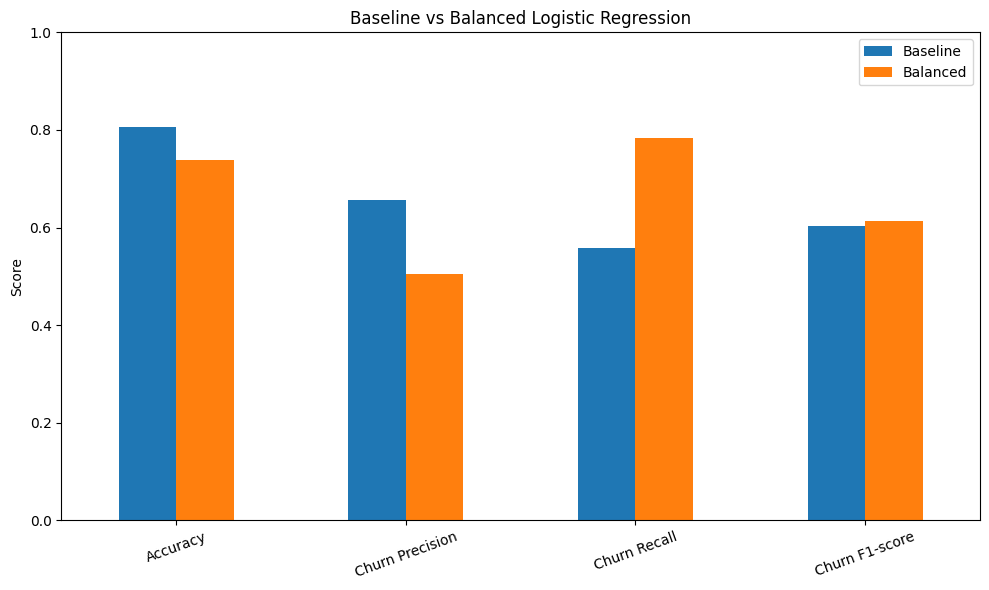


Provisional final model: Balanced Logistic Regression

FINAL MODEL METRICS
model: Balanced Logistic Regression
accuracy: 0.7381 (73.81%)
churn_precision: 0.5043 (50.43%)
churn_recall: 0.7834 (78.34%)
churn_f1_score: 0.6136 (61.36%)

CLASSIFICATION REPORT
              precision    recall  f1-score   support

          No       0.90      0.72      0.80      1035
         Yes       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

CONFUSION MATRIX
[[747 288]
 [ 81 293]]


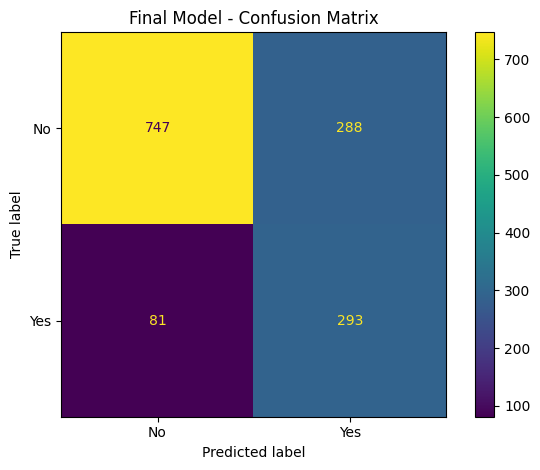

Step 5: All three model files saved.

SAVED MODEL VERIFICATION
Loaded model: Pipeline
Predictions match before and after saving: True

SAMPLE CUSTOMER PREDICTION
Predicted churn: No
Estimated churn probability: 11.77%

PROJECT OUTPUT FILES

models/
 - churn_balanced_model.joblib
 - churn_baseline_model.joblib
 - churn_final_model.joblib

reports/
 - classification_report.json
 - final_confusion_matrix.png
 - final_model_metrics.json
 - model_comparison.csv
 - model_comparison.png

outputs/
 - test_predictions.csv

Root-level file:
 - requirements.txt

PROJECT COMPLETION BATCH FINISHED!
Model saved, reloaded, and prediction verification passed.
Next: full project review and end-to-end validation.


In [37]:

# ============================================================
# CUSTOMER CHURN PREDICTION - FINAL PROJECT COMPLETION BATCH
# Assumes the earlier data preparation and model cells ran.
# ============================================================

import os
import json
import joblib
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from datetime import datetime
from importlib.metadata import version, PackageNotFoundError

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ------------------------------------------------------------
# 1. CREATE PROJECT OUTPUT FOLDERS
# ------------------------------------------------------------

models_dir = Path("models")
reports_dir = Path("reports")
outputs_dir = Path("outputs")

models_dir.mkdir(exist_ok=True)
reports_dir.mkdir(exist_ok=True)
outputs_dir.mkdir(exist_ok=True)

print("Step 1: Project folders created.")

# ------------------------------------------------------------
# 2. COMPARE THE TWO TRAINED MODELS
# ------------------------------------------------------------

model_comparison = pd.DataFrame({
    "Baseline": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, pos_label="Yes"),
        recall_score(y_test, y_pred, pos_label="Yes"),
        f1_score(y_test, y_pred, pos_label="Yes")
    ],
    "Balanced": [
        accuracy_score(y_test, y_pred_balanced),
        precision_score(y_test, y_pred_balanced, pos_label="Yes"),
        recall_score(y_test, y_pred_balanced, pos_label="Yes"),
        f1_score(y_test, y_pred_balanced, pos_label="Yes")
    ]
}, index=[
    "Accuracy",
    "Churn Precision",
    "Churn Recall",
    "Churn F1-score"
])

print("\nMODEL COMPARISON")
print(model_comparison.round(4))

model_comparison.to_csv(
    reports_dir / "model_comparison.csv"
)

# Save comparison chart
ax = model_comparison.plot(
    kind="bar",
    figsize=(10, 6)
)
ax.set_title("Baseline vs Balanced Logistic Regression")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(
    reports_dir / "model_comparison.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# 3. SELECT A PROVISIONAL FINAL MODEL
# ------------------------------------------------------------
# The balanced model has higher churn recall and a slightly
# higher churn F1-score on our current test split.
# This selection is provisional until further validation.

final_model = balanced_model
final_model_name = "Balanced Logistic Regression"

print("\nProvisional final model:", final_model_name)

# ------------------------------------------------------------
# 4. EVALUATE THE SELECTED MODEL
# ------------------------------------------------------------

y_pred_final = final_model.predict(X_test)

final_metrics = {
    "model": final_model_name,
    "accuracy": float(accuracy_score(y_test, y_pred_final)),
    "churn_precision": float(
        precision_score(y_test, y_pred_final, pos_label="Yes")
    ),
    "churn_recall": float(
        recall_score(y_test, y_pred_final, pos_label="Yes")
    ),
    "churn_f1_score": float(
        f1_score(y_test, y_pred_final, pos_label="Yes")
    )
}

print("\nFINAL MODEL METRICS")
for metric, value in final_metrics.items():
    if metric != "model":
        print(f"{metric}: {value:.4f} ({value:.2%})")
    else:
        print(f"{metric}: {value}")

print("\nCLASSIFICATION REPORT")
print(classification_report(y_test, y_pred_final))

# Save classification report
report_dict = classification_report(
    y_test,
    y_pred_final,
    output_dict=True
)

with open(
    reports_dir / "classification_report.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(report_dict, file, indent=4)

# Save confusion matrix
final_cm = confusion_matrix(
    y_test,
    y_pred_final,
    labels=["No", "Yes"]
)

print("CONFUSION MATRIX")
print(final_cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=final_cm,
    display_labels=["No", "Yes"]
)
disp.plot()
plt.title("Final Model - Confusion Matrix")
plt.tight_layout()
plt.savefig(
    reports_dir / "final_confusion_matrix.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# 5. SAVE BOTH MODELS AND THE PROVISIONAL FINAL MODEL
# ------------------------------------------------------------

joblib.dump(
    model_pipeline,
    models_dir / "churn_baseline_model.joblib"
)

joblib.dump(
    balanced_model,
    models_dir / "churn_balanced_model.joblib"
)

joblib.dump(
    final_model,
    models_dir / "churn_final_model.joblib"
)

print("Step 5: All three model files saved.")

# ------------------------------------------------------------
# 6. RELOAD THE SAVED FINAL MODEL AND VERIFY IT
# ------------------------------------------------------------

loaded_model = joblib.load(
    models_dir / "churn_final_model.joblib"
)

loaded_predictions = loaded_model.predict(X_test)

predictions_match = (
    (loaded_predictions == y_pred_final).all()
)

print("\nSAVED MODEL VERIFICATION")
print("Loaded model:", type(loaded_model).__name__)
print("Predictions match before and after saving:",
      predictions_match)

if not predictions_match:
    raise RuntimeError(
        "Saved model verification failed. Check the model files."
    )

# ------------------------------------------------------------
# 7. TEST A SAMPLE CUSTOMER
# ------------------------------------------------------------

sample_customer = X_test.iloc[[0]]

sample_prediction = loaded_model.predict(
    sample_customer
)[0]

sample_probabilities = loaded_model.predict_proba(
    sample_customer
)[0]

model_classes = list(
    loaded_model.named_steps["model"].classes_
)

yes_index = model_classes.index("Yes")
sample_churn_probability = float(
    sample_probabilities[yes_index]
)

print("\nSAMPLE CUSTOMER PREDICTION")
print("Predicted churn:", sample_prediction)
print(
    f"Estimated churn probability: "
    f"{sample_churn_probability:.2%}"
)

# ------------------------------------------------------------
# 8. SAVE TEST PREDICTIONS
# ------------------------------------------------------------

prediction_results = pd.DataFrame({
    "actual_churn": y_test,
    "predicted_churn": y_pred_final
}, index=X_test.index)

prediction_results.to_csv(
    outputs_dir / "test_predictions.csv",
    index_label="original_row_index"
)

# ------------------------------------------------------------
# 9. SAVE FINAL METRICS AND MODEL INFORMATION
# ------------------------------------------------------------

final_metrics["test_rows"] = int(len(X_test))
final_metrics["training_rows"] = int(len(X_train))
final_metrics["input_feature_count"] = int(X_train.shape[1])
final_metrics["created_at"] = datetime.now().isoformat(
    timespec="seconds"
)

with open(
    reports_dir / "final_model_metrics.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(final_metrics, file, indent=4)

# ------------------------------------------------------------
# 10. CREATE REQUIREMENTS FILE
# ------------------------------------------------------------

packages = [
    "pandas",
    "numpy",
    "scikit-learn",
    "matplotlib",
    "joblib"
]

requirements_lines = []

for package in packages:
    try:
        installed_version = version(package)
        requirements_lines.append(
            f"{package}=={installed_version}"
        )
    except PackageNotFoundError:
        requirements_lines.append(package)

with open(
    "requirements.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write("\n".join(requirements_lines) + "\n")

# ------------------------------------------------------------
# 11. SHOW THE GENERATED FILES
# ------------------------------------------------------------

print("\nPROJECT OUTPUT FILES")
for folder in [models_dir, reports_dir, outputs_dir]:
    print(f"\n{folder}/")
    for path in sorted(folder.iterdir()):
        if path.is_file():
            print(" -", path.name)

print("\nRoot-level file:")
print(" - requirements.txt")

print("\nPROJECT COMPLETION BATCH FINISHED!")
print("Model saved, reloaded, and prediction verification passed.")
print("Next: full project review and end-to-end validation.")
